# **Goldilock Zone Investigators**
---
### Tanisha Ravindran and Neal Kaushik Sharma
---

**Can we predict an exoplanet's temperature using planetary, orbital, and stellar features?**

Target/label: **Temp. (K)**

Features:
- Mass
- Radius
- Orbital period
- Semi-major axis
- Discovery method
- Discovery year
- Distance
- Host star mass
- Host star temperature

This is a regression problem because we are predicting a numerical value.

Direct Link to our Dataset: [Exoplanets-planets-outside-our-galaxy](https://www.kaggle.com/datasets/diaaessam/exoplanets-planets-outside-our-galaxy)

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

df = pd.read_csv('exoplanets.csv')

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (4855, 12)


,Name,Mass (MJ),Radius (RJ),Period (days),Semi-major axis (AU),Temp. (K),Discovery method,Disc. Year,Distance (ly),Host star mass (M☉),Host star temp. (K),Remarks
0,16 Cygni Bb,2.38,NaN,799.5,1.66,NaN,radial vel.,1996.0,68.99,1.04,5750,NaN
1,23 Librae b,1.61,NaN,258.18,0.81,NaN,radial vel.,1999.0,85.46,1.07,5736,NaN
2,47 Ursae Majoris b,2.53,NaN,1078,2.1,NaN,radial vel.,1996.0,45.02,1.08,5892,Proper name Taphao Thong
3,51 Pegasi b,0.46,NaN,4.230785,0.0527,NaN,radial vel.,1995.0,50.45,1.12,5793,Proper name Dimidium; previously informally na...
4,55 Cancri b,0.8306,NaN,14.65152,0.115227,700,radial vel.,1996.0,41.06,0.905,5196,Proper name Galileo


In [ ]:
df_clean = df.copy()

numeric_cols = ['Mass (MJ)', 'Radius (RJ)', 'Period (days)', 'Semi-major axis (AU)', 'Temp. (K)', 'Disc. Year', 'Distance (ly)', 'Host star mass (M☉)', 'Host star temp. (K)']

for col in numeric_cols:
    df_clean[col] = pd.to_numeric(df_clean[col], errors='coerce')

print("Missing values:")
display(df_clean.isna().sum())

df_model = df_clean.dropna(subset=['Temp. (K)']).copy()

print("Original rows:", df_clean.shape[0])
print("Rows with temperature:", df_model.shape[0])

Missing values:


,0
Name,0
Mass (MJ),3381
Radius (RJ),1897
Period (days),1086
Semi-major axis (AU),2634
Temp. (K),4248
Discovery method,0
Disc. Year,4444
Distance (ly),2035
Host star mass (M☉),1423


Original rows: 4855
Rows with temperature: 607


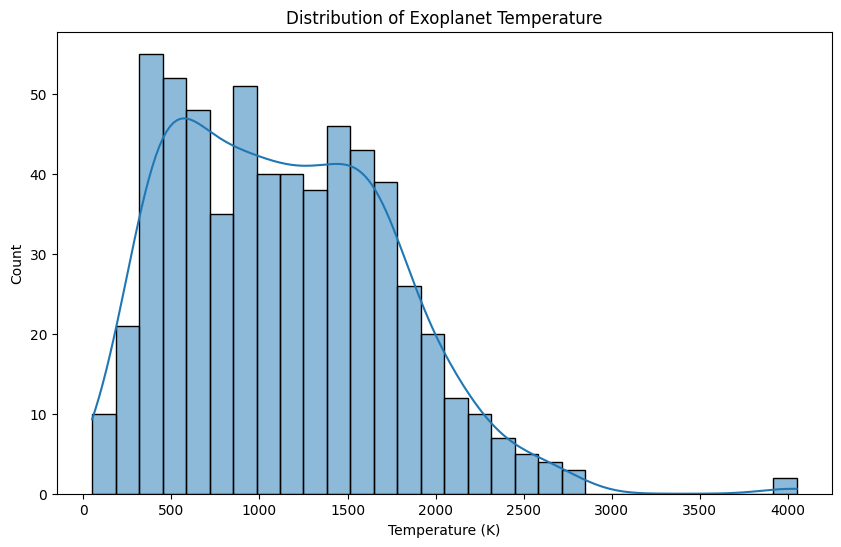

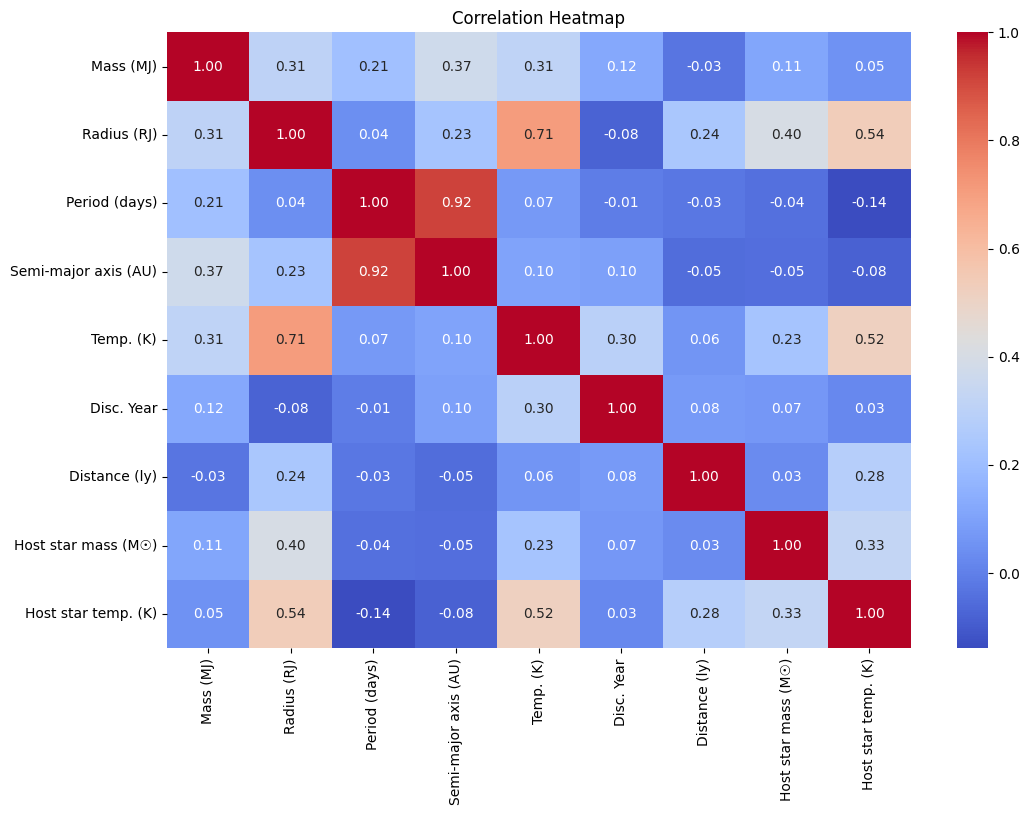

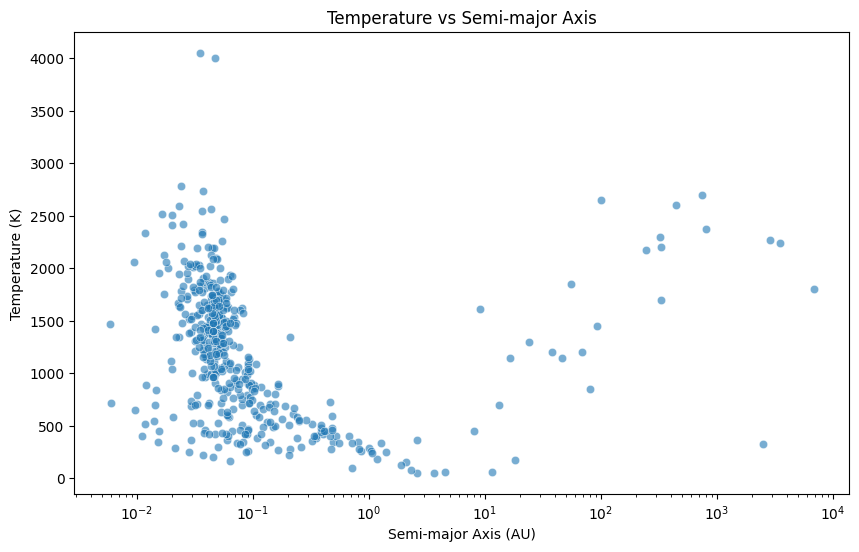

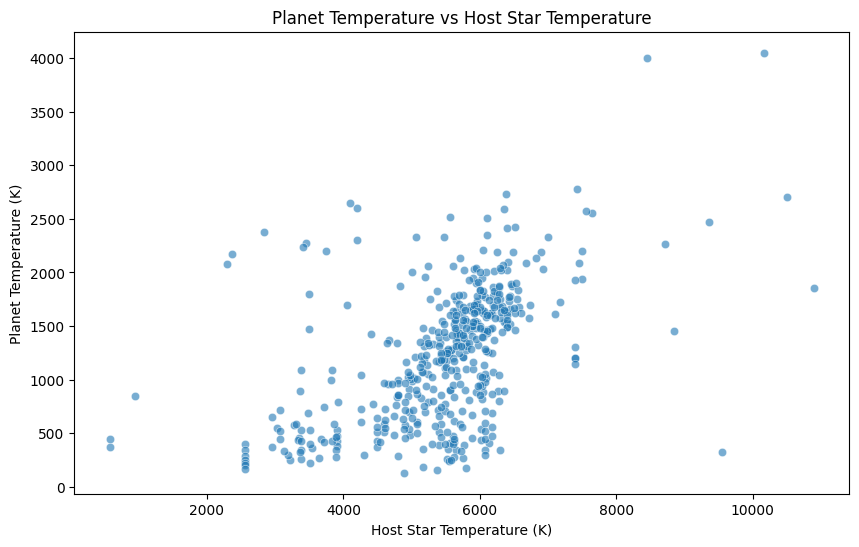

,Temp. (K)
Temp. (K),1.000000
Radius (RJ),0.708871
Host star temp. (K),0.515341
Mass (MJ),0.311257
Disc. Year,0.296043
Host star mass (M☉),0.227739
Semi-major axis (AU),0.103794
Period (days),0.073799
Distance (ly),0.058502


In [ ]:
plt.figure(figsize=(10, 6))
sns.histplot(df_model['Temp. (K)'], bins=30, kde=True)
plt.title('Distribution of Exoplanet Temperature')
plt.xlabel('Temperature (K)')
plt.ylabel('Count')
plt.show()

corr_cols = ['Mass (MJ)', 'Radius (RJ)', 'Period (days)', 'Semi-major axis (AU)', 'Temp. (K)', 'Disc. Year', 'Distance (ly)', 'Host star mass (M☉)', 'Host star temp. (K)']

plt.figure(figsize=(12, 8))
sns.heatmap(df_model[corr_cols].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap')
plt.show()

# Temperature vs semi-major axis
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_model, x='Semi-major axis (AU)', y='Temp. (K)', alpha=0.6)
plt.xscale('log')
plt.title('Temperature vs Semi-major Axis')
plt.xlabel('Semi-major Axis (AU)')
plt.ylabel('Temperature (K)')
plt.show()

# Temperature vs host star temperature
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_model, x='Host star temp. (K)', y='Temp. (K)', alpha=0.6)
plt.title('Planet Temperature vs Host Star Temperature')
plt.xlabel('Host Star Temperature (K)')
plt.ylabel('Planet Temperature (K)')
plt.show()

# Correlation with target
df_model[corr_cols].corr()['Temp. (K)'].sort_values(ascending=False)

In [ ]:
df_model['Log Mass'] = np.log1p(df_model['Mass (MJ)'])
df_model['Log Radius'] = np.log1p(df_model['Radius (RJ)'])
df_model['Log Period'] = np.log1p(df_model['Period (days)'])
df_model['Log Semi-major Axis'] = np.log1p(df_model['Semi-major axis (AU)'])
df_model['Log Distance'] = np.log1p(df_model['Distance (ly)'])

features = ['Log Mass', 'Log Radius', 'Log Period', 'Log Semi-major Axis', 'Disc. Year', 'Log Distance', 'Host star mass (M☉)', 'Host star temp. (K)', 'Discovery method']
label = 'Temp. (K)'

model_df = df_model[features + [label]].copy()

num_features = ['Log Mass', 'Log Radius', 'Log Period', 'Log Semi-major Axis', 'Disc. Year', 'Log Distance', 'Host star mass (M☉)', 'Host star temp. (K)']

for col in num_features:
    model_df[col] = model_df[col].replace([np.inf, -np.inf], np.nan)
    model_df[col] = model_df[col].fillna(model_df[col].median())

model_df['Discovery method'] = model_df['Discovery method'].fillna('Unknown')

model_df_encoded = pd.get_dummies(model_df, columns=['Discovery method'], drop_first=True)

print("Shape:", model_df_encoded.shape)
display(model_df_encoded.head())

Shape: (607, 13)


,Log Mass,Log Radius,Log Period,Log Semi-major Axis,Disc. Year,Log Distance,Host star mass (M☉),Host star temp. (K),Temp. (K),Discovery method_microlensing,Discovery method_radial vel.,Discovery method_timing,Discovery method_transit
4,0.604644,0.737164,2.750568,0.109058,1996.0,3.739097,0.905,5196.0,700.0,False,True,False,False
10,0.398776,0.737164,1.506135,0.048790,1999.0,4.564869,1.290,6117.0,1260.0,False,True,False,False
12,0.765468,0.737164,2.460333,0.088469,1999.0,4.654912,0.920,5387.0,720.0,False,True,False,False
16,0.444686,0.737164,3.233000,0.139762,1999.0,4.175617,0.660,4976.0,486.0,False,True,False,False
18,0.548121,0.871293,1.509562,0.045996,1999.0,5.067646,1.230,6091.0,1459.0,False,True,False,False


In [ ]:
X = model_df_encoded.drop(columns=[label])
y = model_df_encoded[label]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])

Training rows: 485
Testing rows: 122


,Model,R2,MAE,RMSE
1,KNN Regression,0.656271,218.675475,349.289934
2,Decision Tree Regression,0.541133,272.927243,403.572570
0,Linear Regression,0.356679,304.210000,477.850564


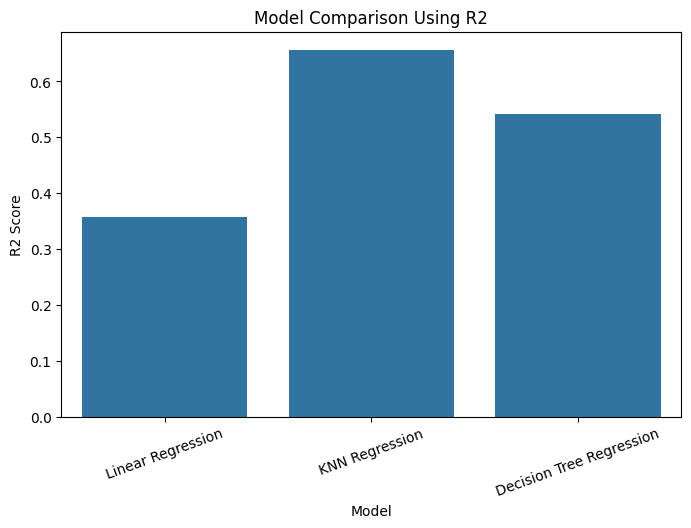

In [ ]:
def evaluate_model(model, X_train_data, X_test_data, y_train, y_test):
    model.fit(X_train_data, y_train)
    predictions = model.predict(X_test_data)
    r2 = r2_score(y_test, predictions)
    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    return r2, mae, rmse, predictions

linear_model = LinearRegression()
linear_r2, linear_mae, linear_rmse, linear_predictions = evaluate_model(linear_model, X_train_scaled, X_test_scaled, y_train, y_test)

knn_model = KNeighborsRegressor(n_neighbors=5)
knn_r2, knn_mae, knn_rmse, knn_predictions = evaluate_model(knn_model, X_train_scaled, X_test_scaled, y_train, y_test)

tree_model = DecisionTreeRegressor(max_depth=5, random_state=42)
tree_r2, tree_mae, tree_rmse, tree_predictions = evaluate_model(tree_model, X_train, X_test, y_train, y_test)

results = pd.DataFrame({'Model': ['Linear Regression', 'KNN Regression', 'Decision Tree Regression'], 'R2': [linear_r2, knn_r2, tree_r2], 'MAE': [linear_mae, knn_mae, tree_mae], 'RMSE': [linear_rmse, knn_rmse, tree_rmse]})

display(results.sort_values(by='R2', ascending=False))

plt.figure(figsize=(8, 5))
sns.barplot(data=results, x='Model', y='R2')
plt.title('Model Comparison Using R2')
plt.ylabel('R2 Score')
plt.xlabel('Model')
plt.xticks(rotation=20)
plt.show()

,Model,Mean CV R2,CV R2 Std
1,KNN Regression,0.617626,0.151893
2,Decision Tree Regression,0.550845,0.152478
0,Linear Regression,0.159485,0.635645


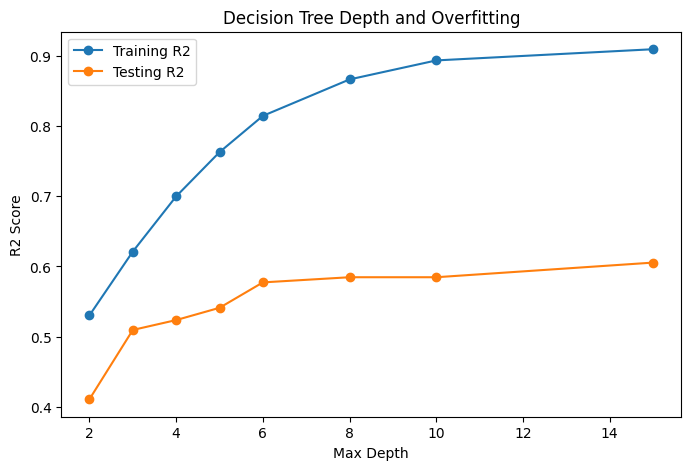

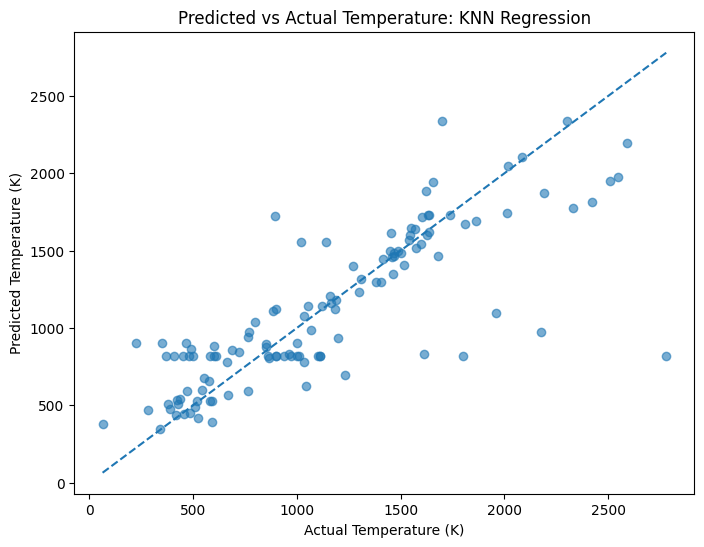

In [ ]:
linear_cv = cross_val_score(linear_model, X_train_scaled, y_train, cv=5, scoring='r2')
knn_cv = cross_val_score(knn_model, X_train_scaled, y_train, cv=5, scoring='r2')
tree_cv = cross_val_score(tree_model, X_train, y_train, cv=5, scoring='r2')

cv_results = pd.DataFrame({
    'Model': ['Linear Regression', 'KNN Regression', 'Decision Tree Regression'],
    'Mean CV R2': [linear_cv.mean(), knn_cv.mean(), tree_cv.mean()],
    'CV R2 Std': [linear_cv.std(), knn_cv.std(), tree_cv.std()]
})

display(cv_results.sort_values(by='Mean CV R2', ascending=False))

depths = [2, 3, 4, 5, 6, 8, 10, 15]
train_scores = []
test_scores = []

for depth in depths:
    temp_tree = DecisionTreeRegressor(max_depth=depth, random_state=42)
    temp_tree.fit(X_train, y_train)

    train_scores.append(temp_tree.score(X_train, y_train))
    test_scores.append(temp_tree.score(X_test, y_test))

plt.figure(figsize=(8, 5))
plt.plot(depths, train_scores, marker='o', label='Training R2')
plt.plot(depths, test_scores, marker='o', label='Testing R2')
plt.title('Decision Tree Depth and Overfitting')
plt.xlabel('Max Depth')
plt.ylabel('R2 Score')
plt.legend()
plt.show()

best_model_name = results.sort_values(by='R2', ascending=False).iloc[0]['Model']

if best_model_name == 'Linear Regression':
    best_predictions = linear_predictions
elif best_model_name == 'KNN Regression':
    best_predictions = knn_predictions
else:
    best_predictions = tree_predictions

plt.figure(figsize=(8, 6))
plt.scatter(y_test, best_predictions, alpha=0.6)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], linestyle='--')
plt.title('Predicted vs Actual Temperature: ' + best_model_name)
plt.xlabel('Actual Temperature (K)')
plt.ylabel('Predicted Temperature (K)')
plt.show()

Hot Jupiters: 228
Lonely Giants: 37
Puffy Planets: 44
Super Dense Planets: 139
Mismatched Systems: 29
Planets in Rough Habitable Zone: 151


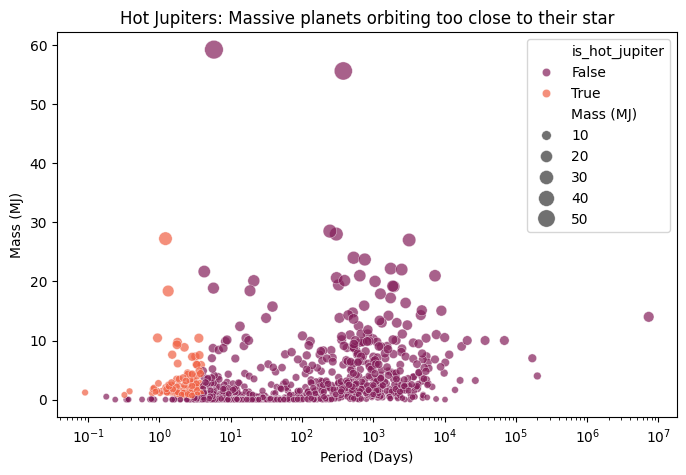

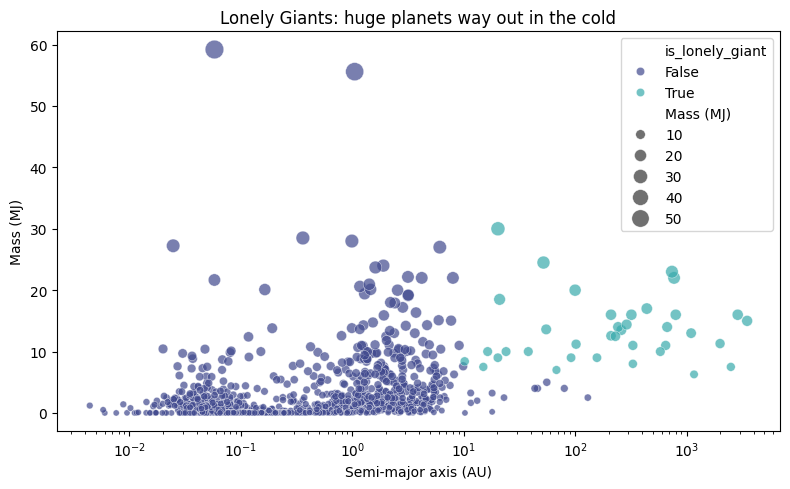

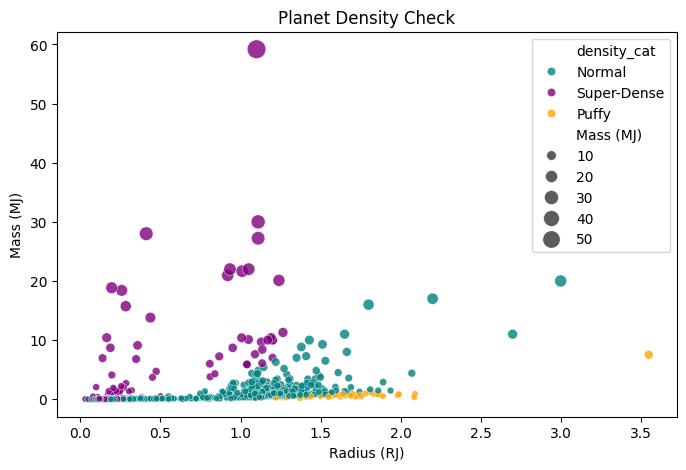

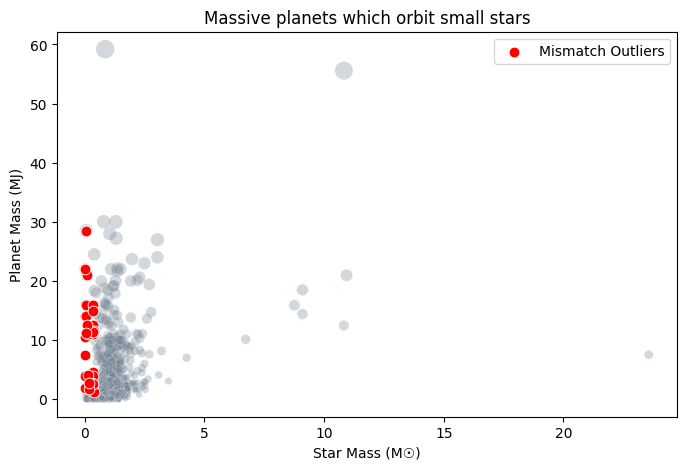

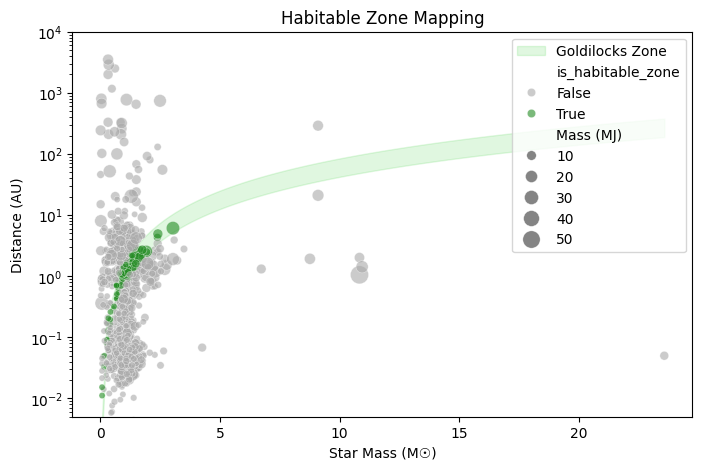

In [ ]:
# Extra plots from previous submission

df_extra = df_clean.copy()

extra_cols = ['Mass (MJ)', 'Radius (RJ)', 'Period (days)', 'Semi-major axis (AU)', 'Host star mass (M☉)', 'Temp. (K)']
for col in extra_cols:
    df_extra[col] = pd.to_numeric(df_extra[col], errors='coerce')

df_extra['is_hot_jupiter'] = (df_extra['Mass (MJ)'] > 0.5) & (df_extra['Period (days)'] < 4)
df_extra['is_lonely_giant'] = (df_extra['Mass (MJ)'] > 5) & (df_extra['Semi-major axis (AU)'] > 10)
df_extra['Density Proxy'] = df_extra['Mass (MJ)'] / (df_extra['Radius (RJ)'] ** 3)
df_extra['is_puffy'] = (df_extra['Radius (RJ)'] > 1.2) & (df_extra['Density Proxy'] < 0.2)
df_extra['is_super_dense'] = df_extra['Density Proxy'] > 4
df_extra['is_mismatch'] = (df_extra['Mass (MJ)'] > 1) & (df_extra['Host star mass (M☉)'] < 0.4)
df_extra['hz_inner'] = 0.75 * np.sqrt(df_extra['Host star mass (M☉)'] ** 3.5)
df_extra['hz_outer'] = 1.5 * np.sqrt(df_extra['Host star mass (M☉)'] ** 3.5)
df_extra['is_habitable_zone'] = (df_extra['Semi-major axis (AU)'] >= df_extra['hz_inner']) & (df_extra['Semi-major axis (AU)'] <= df_extra['hz_outer'])

print("Hot Jupiters:", df_extra['is_hot_jupiter'].sum())
print("Lonely Giants:", df_extra['is_lonely_giant'].sum())
print("Puffy Planets:", df_extra['is_puffy'].sum())
print("Super Dense Planets:", df_extra['is_super_dense'].sum())
print("Mismatched Systems:", df_extra['is_mismatch'].sum())
print("Planets in Rough Habitable Zone:", df_extra['is_habitable_zone'].sum())

df_orbit = df_extra.dropna(subset=['Period (days)', 'Mass (MJ)']).copy()
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df_orbit, x='Period (days)', y='Mass (MJ)', hue='is_hot_jupiter', palette='rocket', size='Mass (MJ)', sizes=(20, 180), alpha=0.7)
plt.xscale('log')
plt.title('Hot Jupiters: Massive planets orbiting too close to their star')
plt.xlabel('Period (Days)')
plt.ylabel('Mass (MJ)')
plt.legend(loc='upper right')
plt.show()

df_dist = df_extra.dropna(subset=['Semi-major axis (AU)', 'Mass (MJ)']).copy()
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df_dist, x='Semi-major axis (AU)', y='Mass (MJ)', hue='is_lonely_giant', palette='mako', size='Mass (MJ)', sizes=(20, 180), alpha=0.7)
plt.xscale('log')
plt.title('Lonely Giants: huge planets way out in the cold')
plt.xlabel('Semi-major axis (AU)')
plt.ylabel('Mass (MJ)')
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

df_density = df_extra.dropna(subset=['Mass (MJ)', 'Radius (RJ)', 'Density Proxy']).copy()
df_density['density_cat'] = 'Normal'
df_density.loc[df_density['is_puffy'], 'density_cat'] = 'Puffy'
df_density.loc[df_density['is_super_dense'], 'density_cat'] = 'Super-Dense'
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df_density, x='Radius (RJ)', y='Mass (MJ)', hue='density_cat', palette={'Puffy': 'orange', 'Super-Dense': 'purple', 'Normal': 'teal'}, size='Mass (MJ)', sizes=(20, 180), alpha=0.8)
plt.title('Planet Density Check')
plt.xlabel('Radius (RJ)')
plt.ylabel('Mass (MJ)')
plt.legend(loc='upper right')
plt.show()

df_sys = df_extra.dropna(subset=['Mass (MJ)', 'Host star mass (M☉)']).copy()
mismatched_systems = df_sys[df_sys['is_mismatch']]
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df_sys, x='Host star mass (M☉)', y='Mass (MJ)', color='slategrey', alpha=0.3, size='Mass (MJ)', sizes=(20, 180), legend=False)
sns.scatterplot(data=mismatched_systems, x='Host star mass (M☉)', y='Mass (MJ)', color='red', s=60, label='Mismatch Outliers')
plt.title('Massive planets which orbit small stars')
plt.xlabel('Star Mass (M☉)')
plt.ylabel('Planet Mass (MJ)')
plt.legend(loc='upper right')
plt.show()

df_hz = df_extra.dropna(subset=['Host star mass (M☉)', 'Semi-major axis (AU)', 'Mass (MJ)']).copy()
plt.figure(figsize=(8, 5))
stars_range = np.linspace(df_hz['Host star mass (M☉)'].min(), df_hz['Host star mass (M☉)'].max(), 100)
plt.fill_between(stars_range, 0.75 * np.sqrt(stars_range ** 3.5), 1.5 * np.sqrt(stars_range ** 3.5), color='limegreen', alpha=0.15, label='Goldilocks Zone')
sns.scatterplot(data=df_hz, x='Host star mass (M☉)', y='Semi-major axis (AU)', hue='is_habitable_zone', palette={True: 'forestgreen', False: 'darkgrey'}, size='Mass (MJ)', sizes=(20, 180), alpha=0.6)
plt.yscale('log')
plt.ylim(0.005, 10000)
plt.title('Habitable Zone Mapping')
plt.xlabel('Star Mass (M☉)')
plt.ylabel('Distance (AU)')
plt.legend(loc='upper right')
plt.show()

## Final Conclusion

For Part 3, we changed our project into a regression problem where we predicted exoplanet temperature using planetary, orbital, and stellar features from the dataset. We cleaned the data, handled missing values, applied feature engineering, and tested multiple machine learning models.

We compared Linear Regression, KNN Regression, and Decision Tree Regression using R2, MAE, RMSE, and cross-validation. Out of the three, KNN Regression performed the best with an R2 score of about 0.66.

Our analysis also showed that features like planet radius and host star temperature had stronger relationships with planetary temperature. In addition to the regression task, we explored patterns such as Hot Jupiters, Lonely Giants, and planets that may fall within a rough habitable zone estimate.

Overall, our results showed that exoplanet temperature can be reasonably predicted using surrounding planetary and stellar characteristics, although the dataset still had missing and incomplete values that affected accuracy.